# Week 3: replication presentation


In [1]:
import os
import sys

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

REPO = os.path.abspath("..")          # this notebook lives in <repo>/notebooks
assert os.path.exists(f"{REPO}/metrics.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
from metrics import TARGETS, PERIOD, load_ssp245, global_mean

DATA = os.path.expanduser("~/data/climatebench")
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"

SHORT = {"tas": "tas", "diurnal_temperature_range": "dtr", "pr": "pr", "pr90": "pr90"}
UNIT = {"tas": "K", "diurnal_temperature_range": "K", "pr": "mm/day", "pr90": "mm/day"}

# our models: leaderboard row, published row, prediction file prefix
MODELS = {"Pattern scaling": ("Pattern scaling (ours)", "Pattern scaling (published)", "pattern_scaling"),
          "Pattern scaling, EBM T": ("Pattern scaling, EBM-predicted T (ours)", None, "pattern_scaling_ebm"),
          "Gaussian process": ("Gaussian process (ours)", "Gaussian process (published)", "gp"),
          "Random forest": ("Random forest (ours)", "Random forest (published)", "rf"),
          "CNN-LSTM": ("CNN-LSTM (ours)", "CNN-LSTM (published)", "CNN-LSTM")}

# chart style: thin marks, recessive axes; one hue for ours, gray for published
OURS, PUBLISHED, INK, MUTED, GRID = "#2a78d6", "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10})

board = pd.read_csv(f"{RESULTS}/leaderboard.csv", header=[0, 1], index_col=0)
board.columns = pd.MultiIndex.from_tuples(board.columns)
members = load_ssp245(DATA)
truth = members.mean("member")
print(board.index.tolist())

['Pattern scaling (ours)', 'Pattern scaling (published)', 'Gaussian process (ours)', 'Gaussian process (published)', 'Random forest (ours)', 'Random forest (published)', 'CNN-LSTM (ours)', 'CNN-LSTM (published)', 'Pattern scaling, EBM-predicted T (ours)', 'Variability (paper)', 'Variability floor (ours, approx.)']


## 1. Leaderboard 

Total NRMSE (spatial + 5 × global) over 2080–2100 against the `ssp245` ensemble mean, lower is better. Compare models within a
target, not across targets: DTR's global-mean change is close to zero, so dividing by it makes every DTR score large.

Two rows have no fair published counterpart:

- **Pattern scaling** (as in the paper) is given the true `ssp245` global-mean temperature at test time, so it is a reference
  point, not an emulator. **Pattern scaling, EBM T** predicts that temperature from the forcings instead (our fair version).
- **Variability floor**: the approximate score of a *perfect* emulator, limited only by internal variability.

In [2]:
totals = board.xs("Total", axis=1, level=1)
rows = {}
for name, (ours, published, _) in MODELS.items():
    rows[(name, "ours")] = totals.loc[ours]
    if published:
        rows[(name, "published")] = totals.loc[published]
rows[("Variability floor", "ours, approx.")] = totals.loc["Variability floor (ours, approx.)"]
rows[("Variability", "paper")] = totals.loc["Variability (paper)"]
table = pd.DataFrame(rows).T
table.index.names = ["model", "source"]
table.style.format("{:.3f}").set_caption("Total NRMSE, 2080–2100")

**Ours ÷ published.** Below 1 = we score better. Gray is a match, blue better, red worse.

In [3]:
ratio = pd.DataFrame({name: totals.loc[ours] / totals.loc[published]
                      for name, (ours, published, _) in MODELS.items() if published}).T
ratio.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=0.4, vmax=1.6, axis=None)

,tas,dtr,pr,pr90
Pattern scaling,1.00,0.94,0.91,0.93
Gaussian process,0.63,0.91,0.97,0.99
Random forest,3.69,0.74,1.09,1.13
CNN-LSTM,1.11,0.81,1.06,0.96


**The same table as a chart.** One panel per target, each on its own scale. Filled dot = ours, ring = published, dashed line =
variability floor (the best a perfect emulator could expect).

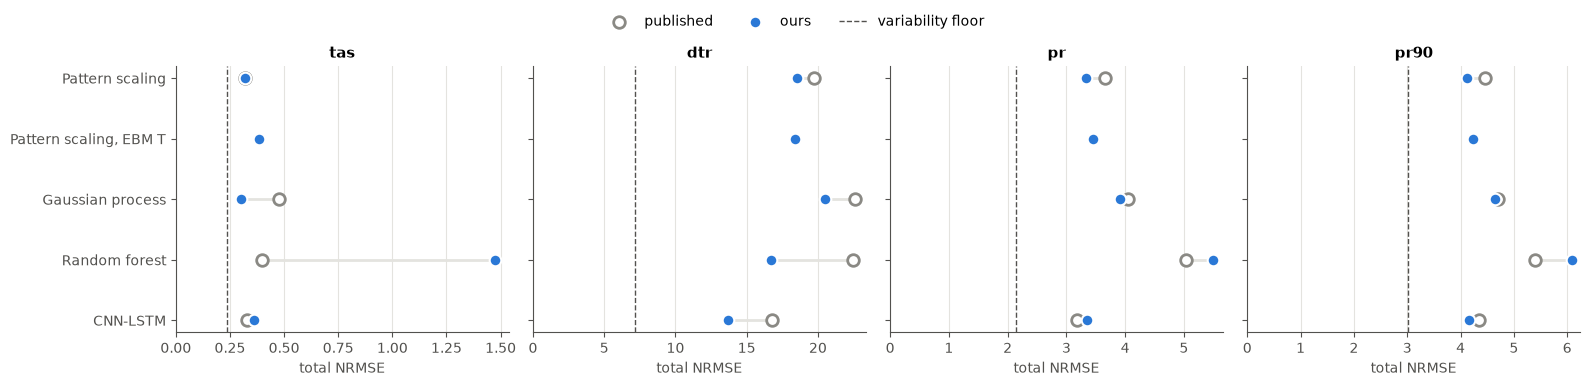

In [4]:
names = list(MODELS)[::-1]                          # top-to-bottom in the order of MODELS
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, var in zip(axes, TARGETS):
    col = SHORT[var]
    y = np.arange(len(names))
    for i, name in enumerate(names):
        ours, published, _ = MODELS[name]
        if published:
            ax.plot([totals.loc[ours, col], totals.loc[published, col]], [i, i], color=GRID, lw=2, zorder=1)
            ax.scatter(totals.loc[published, col], i, s=70, facecolor="white", edgecolor=PUBLISHED, lw=2, zorder=2,
                       label="published" if i == 0 else None)
        ax.scatter(totals.loc[ours, col], i, s=70, color=OURS, edgecolor="white", lw=1.5, zorder=3,
                   label="ours" if i == 0 else None)
    ax.axvline(totals.loc["Variability floor (ours, approx.)", col], color=MUTED, ls="--", lw=1,
               label="variability floor")
    ax.set_title(col)
    ax.set_xlabel("total NRMSE")
    ax.set_xlim(left=0)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, names)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(f"{FIGS}/week3_pres_leaderboard.png", dpi=150, bbox_inches="tight")

## 2. Figure: global-mean temperature on `ssp245` 

What the tas *global* NRMSE measures, and the score with the 5× weight. Gray lines are the three `ssp245` members (their
spread is internal variability), black is their mean, and blue is each model. Shaded: the scored period 2080–2100.

The random forest stands out: its warming levels off at about 1.4 K after 2050 while the truth keeps rising, and over
2080–2100 it is about 0.5 K too cold (1.58 vs 2.07 K). A tree predicts a constant in each leaf, an average of training years,
so it can't interpolate between training scenarios: `ssp245`'s late century sits between `ssp126` and `ssp370`, and the forest
returns a mix of their leaves.

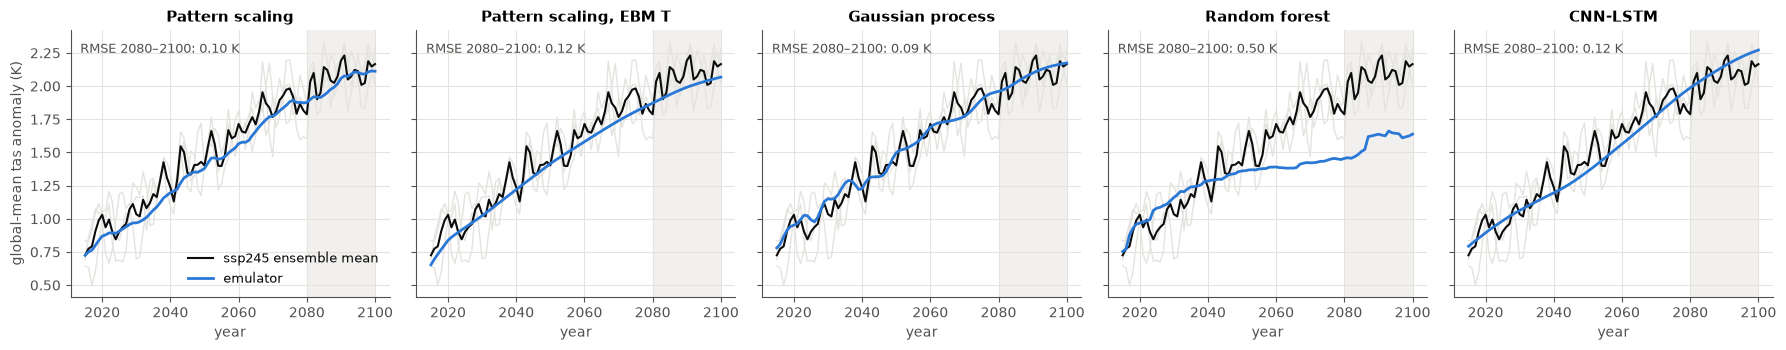

In [5]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(18, 3.6), sharey=True)
for ax, (name, (_, _, prefix)) in zip(axes, MODELS.items()):
    pred = xr.open_dataset(f"{RESULTS}/{prefix}_ssp245.nc")
    for m in members.member.values:
        ax.plot(truth.time, global_mean(members["tas"].sel(member=m)), color=GRID, lw=1)
    ax.plot(truth.time, global_mean(truth["tas"]), color=INK, lw=1.5, label="ssp245 ensemble mean")
    ax.plot(pred.time, global_mean(pred["tas"]), color=OURS, lw=2, label="emulator")
    ax.axvspan(PERIOD.start, PERIOD.stop, color=GRID, alpha=0.5, lw=0)
    err = float(np.sqrt(((global_mean(pred["tas"]) - global_mean(truth["tas"])).sel(time=PERIOD) ** 2).mean()))
    ax.set_title(name)
    ax.text(0.03, 0.95, f"RMSE 2080–2100: {err:.2f} K", transform=ax.transAxes, va="top", color=MUTED, fontsize=9)
    ax.set_xlabel("year")
axes[0].set_ylabel("global-mean tas anomaly (K)")
axes[0].legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIGS}/week3_pres_global_tas.png", dpi=150, bbox_inches="tight")

**Other figure candidates** (already saved by the model notebooks):

- `figures/week3_difference_maps.png`: prediction − truth for every model and target (Task 5).
- `figures/week3_ps_global_T.png`: oracle vs EBM-predicted global temperature for pattern scaling.
- `figures/week3_gp_uncertainty.png`: whether the GP's predictive variance is calibrated.
- `figures/week3_tas_spread.png`: where the five CNN-LSTM seeds disagree.

![difference maps](../figures/week3_difference_maps.png)

## 3. Surprises 

**Honest tuning gave a worse random forest.** Leave-one-scenario-out CV, without `ssp245`, chose `max_features='sqrt'`;
   the paper's all-features setting scores far better on tas. The CV couldn't tell them apart: the mean CV scores of all
   15 candidates lie within 1.055–1.116, and the chosen `sqrt` candidate beats the best all-features one on 4 held-out
   scenarios (one a tie) and loses on 2. Our tas total is 3.7× the published one. Six training scenarios are a thin basis for tuning.


### Evidence: the CV could not tell the settings apart

The RF's hyperparameters were chosen by leave-one-scenario-out CV over the six training scenarios
(`Week3_RandomForest.ipynb`, section 4). Each candidate's RMSE on a held-out scenario is divided by the best candidate's RMSE on
that scenario, so 1.0 = best on that fold. The scores are in `results/rf_cv_scores.csv`; the candidates are rebuilt here with the
same search space and seed.

In [6]:
from sklearn.model_selection import ParameterSampler

# same search space and seed as Week3_RandomForest.ipynb, section 4
SPACE = {"max_depth": [int(x) for x in np.linspace(5, 55, num=11)] + [None],
         "min_samples_split": [5, 10, 15, 25],
         "min_samples_leaf": [4, 8, 12],
         "max_features": [1.0, "sqrt"]}
candidates = pd.DataFrame(ParameterSampler(SPACE, n_iter=15, random_state=0))

cv = pd.read_csv(f"{RESULTS}/rf_cv_scores.csv")
assert cv.candidate.nunique() == len(candidates), "candidate list does not match the saved CV scores"
cv["relative"] = cv.rmse / cv.groupby(["held_out", "target"]).rmse.transform("min")
cv["max_features"] = cv.candidate.map(candidates.max_features.map({1.0: "all 12 features", "sqrt": "sqrt (3 of 12)"}))
tas_cv = cv[cv.target == "tas"]
FOLDS = ["historical", "hist-GHG", "hist-aer", "ssp126", "ssp370", "ssp585"]

summary = (tas_cv.groupby("candidate").relative.mean().rename("mean relative RMSE (tas)").to_frame()
           .join(candidates).sort_values("mean relative RMSE (tas)"))
print(f"spread of the 15 candidates' mean CV score: {summary.iloc[0, 0]:.3f} to {summary.iloc[-1, 0]:.3f}")
summary.round(3)

spread of the 15 candidates' mean CV score: 1.055 to 1.116


,mean relative RMSE (tas),min_samples_split,min_samples_leaf,max_features,max_depth
candidate,,,,,
1,1.055,15,4,sqrt,40.0
4,1.055,15,4,sqrt,NaN
8,1.071,25,4,sqrt,5.0
13,1.077,10,12,1.0,20.0
12,1.078,5,4,sqrt,5.0
3,1.083,5,8,sqrt,45.0
11,1.083,15,8,sqrt,NaN
9,1.087,15,12,sqrt,5.0
7,1.090,5,4,1.0,55.0


**Every candidate on every fold (tas).** If the CV could separate the two `max_features` settings, the colors would
form two bands. They don't: which group is lower changes from fold to fold. All features win clearly only on `hist-aer` and
`ssp585`, the two held-out scenarios that need the most extrapolation; `sqrt` wins on the others.

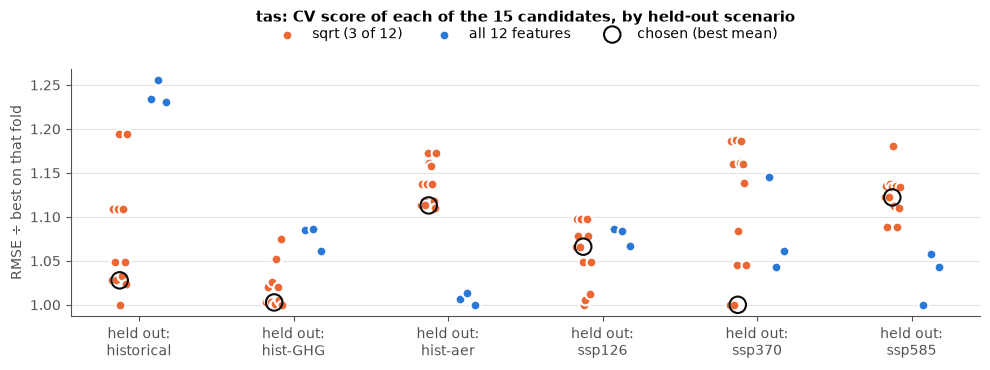

In [7]:
SQRT, ALL = "#eb6834", OURS                      # categorical slots 2 and 1
colors = {"sqrt (3 of 12)": SQRT, "all 12 features": ALL}
fig, ax = plt.subplots(figsize=(10, 3.8))
for j, fold in enumerate(FOLDS):
    d = tas_cv[tas_cv.held_out == fold]
    for k, (label, color) in enumerate(colors.items()):
        v = d[d.max_features == label].relative
        x = j + (k - 0.5) * 0.25 + np.linspace(-0.05, 0.05, len(v))
        ax.scatter(x, v, s=50, color=color, edgecolor="white", lw=1.5, zorder=3, label=label if j == 0 else None)
chosen = tas_cv[tas_cv.candidate == summary.index[0]].set_index("held_out").relative
ax.scatter(np.arange(len(FOLDS)) - 0.125, chosen.loc[FOLDS], s=140, facecolor="none", edgecolor=INK, lw=1.5, zorder=4,
           label="chosen (best mean)")
ax.set_xticks(range(len(FOLDS)), [f"held out:\n{f}" for f in FOLDS])
ax.set_ylabel("RMSE ÷ best on that fold")
ax.set_title("tas: CV score of each of the 15 candidates, by held-out scenario", pad=34)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig(f"{FIGS}/week3_pres_rf_cv.png", dpi=150, bbox_inches="tight")

**Head to head (tas): the chosen `sqrt` candidate vs the best all-features candidate**, RMSE in K on each held-out scenario.

In [8]:
best_all = summary[summary.max_features == 1.0].index[0]
best_sqrt = summary.index[0]
pivot = tas_cv[tas_cv.candidate.isin([best_sqrt, best_all])].pivot(index="held_out", columns="candidate", values="rmse")
pivot = pivot.loc[FOLDS].rename(columns={best_sqrt: f"chosen, sqrt (#{best_sqrt})", best_all: f"best all-features (#{best_all})"})
pivot["lower"] = np.where(pivot.iloc[:, 0] < pivot.iloc[:, 1], "sqrt", "all features")
print(pivot["lower"].value_counts().to_dict())
pivot.round(3)

{'sqrt': 4, 'all features': 2}


candidate,"chosen, sqrt (#1)",best all-features (#13),lower
held_out,,,
historical,0.428,0.513,sqrt
hist-GHG,0.456,0.483,sqrt
hist-aer,0.685,0.616,all features
ssp126,0.713,0.713,sqrt
ssp370,0.595,0.632,sqrt
ssp585,1.334,1.240,all features


**What the CV said vs what `ssp245` said.** The `ssp245` column is a **post-hoc diagnostic** from `Week3_RandomForest.ipynb`,
section 9 (100 trees, 1 seed), run after the submitted model was scored. It was not used to choose anything.

| Setup (tas) | CV says | ssp245 tas total | ssp245 tas spatial | ssp245 tas global |
|---|---|---|---|---|
| Chosen: `max_features='sqrt'`, 6 scenarios | best mean CV score | 1.35 | 0.250 | 0.220 |
| Same, but all 12 features | ~1% worse (mean CV RMSE 0.709 vs 0.702 K; lower on 3 of 6 folds) | 1.22 | 0.110 | 0.223 |
| Paper's hyperparameters, 6 scenarios | not in our search | 1.40 | 0.141 | 0.251 |
| Paper's hyperparameters, 4 scenarios | can't be tested by this CV | 0.79 | 0.165 | 0.125 |
| Published | | 0.40 | 0.108 | 0.058 |

Two lessons:

- The CV score differences between candidates are a few percent, but on `ssp245` the tas spatial error more than doubles
  with `sqrt` (0.250 vs 0.110).
  Six scenarios, three of which need extrapolation, are too few to rank settings reliably.
- The biggest effect is **which scenarios to train on**, and leave-one-scenario-out CV over a fixed training set can't
  measure that choice at all.